In [1]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
!pip install -q -U kaggle
!kaggle datasets download -d sriramr/fruits-fresh-and-rotten-for-classification -p /content/data
!unzip -q /content/data/*.zip -d /content/data
!ls /content/data

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 3.8 MB/s eta 0:00:00
Dataset URL: https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification
License(s): unknown
100% 3.58G/3.58G [00:36<00:00, 104MB/s]

dataset  fruits-fresh-and-rotten-for-classification.zip


In [4]:
!mkdir -p /content/drive/MyDrive/foodshare-ai
!cp /content/data/*.zip /content/drive/MyDrive/foodshare-ai/
!ls -lh /content/drive/MyDrive/foodshare-ai

total 3.6G
-rw------- 1 root root 3.6G Oct 14 08:40 fruits-fresh-and-rotten-for-classification.zip
drwx------ 2 root root 4.0K Oct 13 14:19 models


In [5]:
!ls /content/data/dataset

dataset  test  train


In [6]:
!ls /content/data/dataset/train

freshapples  freshoranges  rottenbanana
freshbanana  rottenapples  rottenoranges


In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np

BASE = '/content/data/dataset'
TRAIN_DIR = f'{BASE}/train'
TEST_DIR = f'{BASE}/test'
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.15, subset='training',
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE)
val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.15, subset='validation',
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE)
test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)

class_names = train_ds.class_names
print(class_names)

data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.15),
], name='data_augmentation')

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

Found 10901 files belonging to 6 classes.
Using 9266 files for training.
Found 10901 files belonging to 6 classes.
Using 1635 files for validation.
Found 2698 files belonging to 6 classes.
['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']


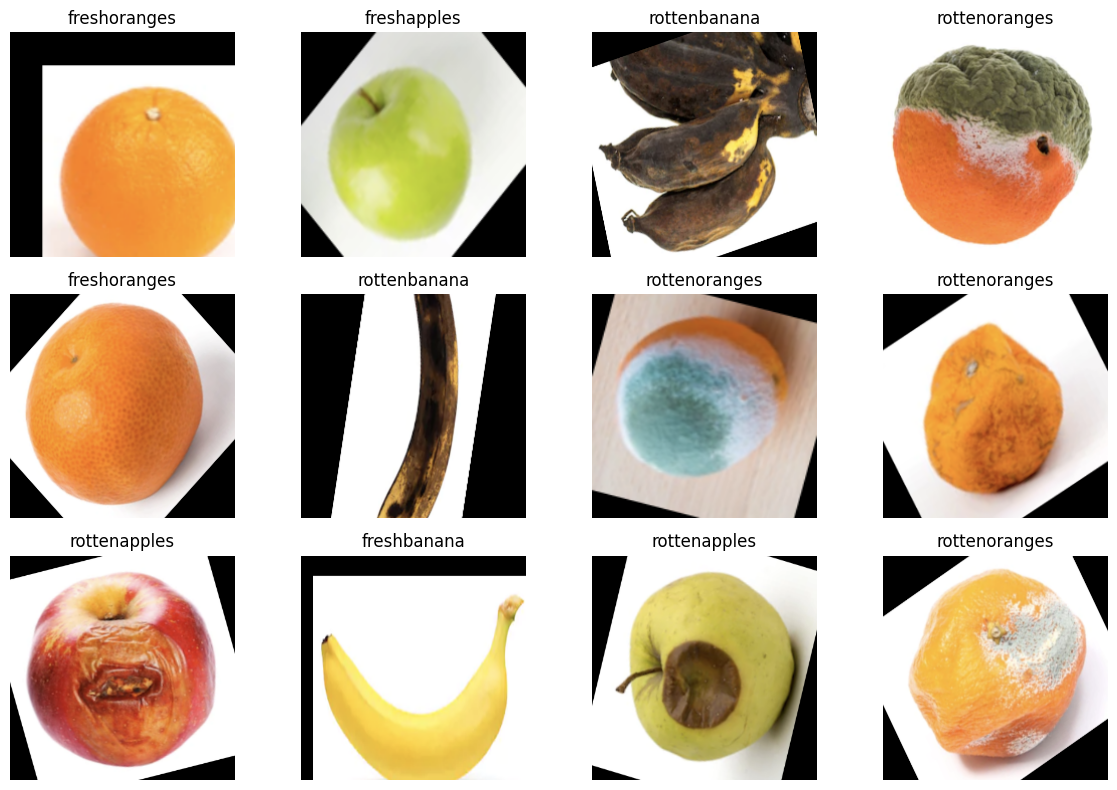

In [8]:
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[labels[i]])
        plt.axis('off')
plt.tight_layout()
plt.show()

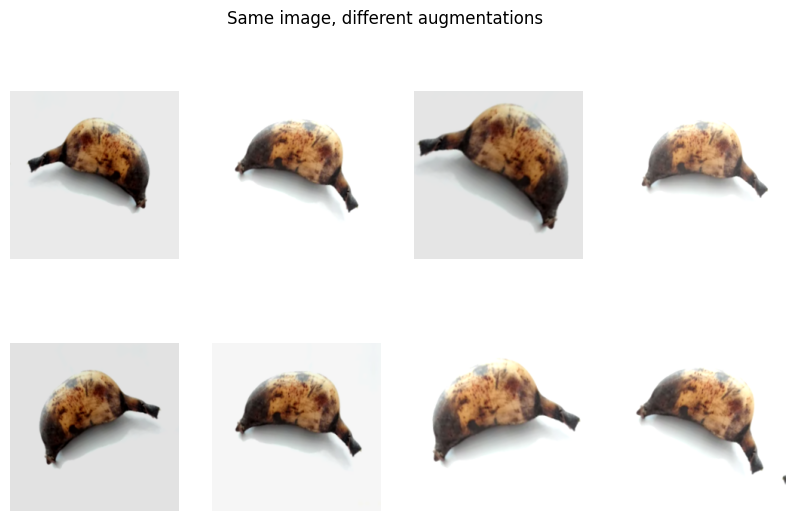

In [9]:
plt.figure(figsize=(10, 6))
for images, _ in train_ds.take(1):
    img = images[0]
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        aug = data_augmentation(tf.expand_dims(img, 0), training=True)
        plt.imshow(aug[0].numpy().astype('uint8'))
        plt.axis('off')
plt.suptitle('Same image, different augmentations')
plt.show()

In [10]:
def build_baseline_cnn(num_classes=6):
    inputs = keras.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs)      # training lo mathrame apply avtundi
    x = layers.Rescaling(1./255)(x)

    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return keras.Model(inputs, outputs, name='baseline_cnn')

baseline = build_baseline_cnn()
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 258,118 (1008.27 KB)

 Trainable params: 258,118 (1008.27 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
import os
SAVE_DIR = '/content/drive/MyDrive/foodshare-ai/models'
os.makedirs(SAVE_DIR, exist_ok=True)

baseline.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

callbacks = [
    keras.callbacks.ModelCheckpoint(
        f'{SAVE_DIR}/baseline_cnn.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, verbose=1),
]

history = baseline.fit(
    train_ds, validation_data=val_ds,
    epochs=20, callbacks=callbacks)

Epoch 1/20
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.3963 - loss: 1.4424
Epoch 1: val_accuracy improved from None to 0.76086, saving model to /content/drive/MyDrive/foodshare-ai/models/baseline_cnn.keras

Epoch 1: finished saving model to /content/drive/MyDrive/foodshare-ai/models/baseline_cnn.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 39s 95ms/step - accuracy: 0.5523 - loss: 1.1289 - val_accuracy: 0.7609 - val_loss: 0.7511 - learning_rate: 0.0010
Epoch 2/20
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.7548 - loss: 0.6939
Epoch 2: val_accuracy improved from 0.76086 to 0.81651, saving model to /content/drive/MyDrive/foodshare-ai/models/baseline_cnn.keras

Epoch 2: finished saving model to /content/drive/MyDrive/foodshare-ai/models/baseline_cnn.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 16s 57ms/step - accuracy: 0.7617 - loss: 0.6665 - val_accuracy: 0.8165 - val_loss: 0.5515 - learning_rate: 0.0010
Epoch 3/20
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.7900 - loss: 0

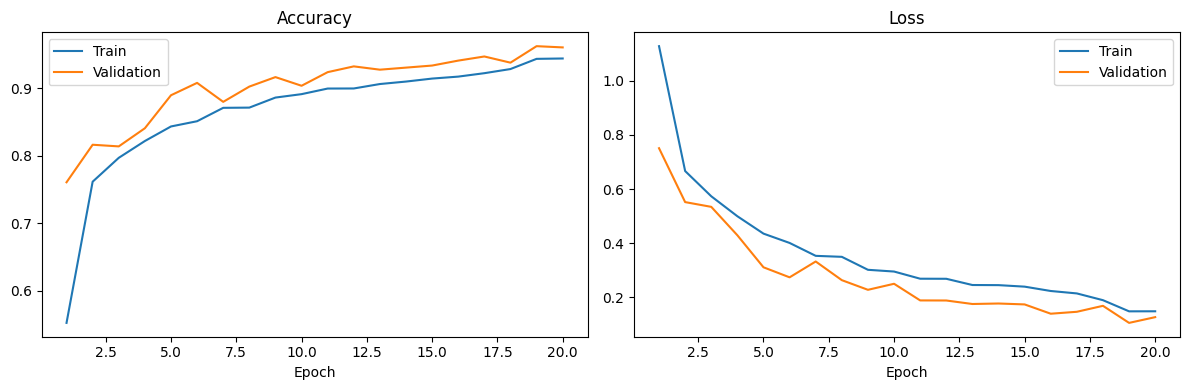

In [12]:
acc, val_acc = history.history['accuracy'], history.history['val_accuracy']
loss, val_loss = history.history['loss'], history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Train')
plt.plot(epochs_range, val_acc, label='Validation')
plt.title('Accuracy'); plt.xlabel('Epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Train')
plt.plot(epochs_range, val_loss, label='Validation')
plt.title('Loss'); plt.xlabel('Epoch'); plt.legend()

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/baseline_curves.png', dpi=150)
plt.show()

In [13]:
best_baseline = keras.models.load_model(f'{SAVE_DIR}/baseline_cnn.keras')
test_loss, test_acc = best_baseline.evaluate(test_ds)
print(f'Baseline CNN test accuracy: {test_acc:.4f}')

85/85 ━━━━━━━━━━━━━━━━━━━━ 12s 140ms/step - accuracy: 0.9678 - loss: 0.0950
Baseline CNN test accuracy: 0.9678


85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
               precision    recall  f1-score   support

  freshapples     0.9773    0.9797    0.9785       395
  freshbanana     0.9895    0.9895    0.9895       381
 freshoranges     0.9757    0.9304    0.9525       388
 rottenapples     0.9299    0.9717    0.9504       601
 rottenbanana     0.9925    0.9962    0.9944       530
rottenoranges     0.9565    0.9280    0.9421       403

     accuracy                         0.9678      2698
    macro avg     0.9702    0.9659    0.9679      2698
 weighted avg     0.9681    0.9678    0.9677      2698



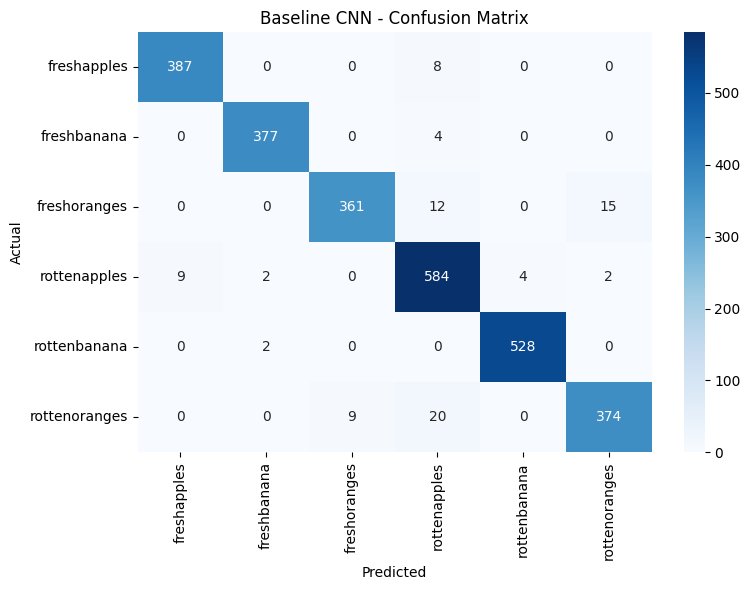

In [14]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(best_baseline.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Baseline CNN - Confusion Matrix')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/baseline_confusion_matrix.png', dpi=150)
plt.show()

In [15]:
fresh_idx = [i for i, c in enumerate(class_names) if c.startswith('fresh')]
yt = np.isin(y_true, fresh_idx).astype(int)   # 1 = fresh, 0 = rotten
yp = np.isin(y_pred, fresh_idx).astype(int)

print(classification_report(yt, yp, target_names=['rotten', 'fresh'], digits=4))
unsafe = int(((yt == 0) & (yp == 1)).sum())
print(f'Rotten predicted as fresh (unsafe errors): {unsafe} out of {int((yt == 0).sum())} rotten images')

              precision    recall  f1-score   support

      rotten     0.9749    0.9857    0.9802      1534
       fresh     0.9808    0.9665    0.9736      1164

    accuracy                         0.9774      2698
   macro avg     0.9778    0.9761    0.9769      2698
weighted avg     0.9774    0.9774    0.9774      2698

Rotten predicted as fresh (unsafe errors): 22 out of 1534 rotten images


In [16]:
!ls /content/data/dataset

dataset  test  train


In [17]:
print(class_names)
print(SAVE_DIR)

['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
/content/drive/MyDrive/foodshare-ai/models


In [18]:
from google.colab import drive
drive.mount('/content/drive')

import os
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np

SAVE_DIR = '/content/drive/MyDrive/foodshare-ai/models'
BASE = '/content/data/dataset'
TRAIN_DIR = f'{BASE}/train'
TEST_DIR = f'{BASE}/test'
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.15, subset='training',
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE)
val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.15, subset='validation',
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE)
test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)

class_names = train_ds.class_names
print(class_names)

data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.15),
], name='data_augmentation')

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found 10901 files belonging to 6 classes.
Using 9266 files for training.
Found 10901 files belonging to 6 classes.
Using 1635 files for validation.
Found 2698 files belonging to 6 classes.
['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']


In [19]:
from google.colab import drive
drive.mount('/content/drive')

import os
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np

# Dataset lekapothe Drive zip nunchi unzip cheyyi
if not os.path.exists('/content/data/dataset/train'):
    os.makedirs('/content/data', exist_ok=True)
    os.system('unzip -q /content/drive/MyDrive/foodshare-ai/*.zip -d /content/data')
print(os.listdir('/content/data/dataset'))

SAVE_DIR = '/content/drive/MyDrive/foodshare-ai/models'
BASE = '/content/data/dataset'
TRAIN_DIR = f'{BASE}/train'
TEST_DIR = f'{BASE}/test'
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.15, subset='training',
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE)
val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.15, subset='validation',
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE)
test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)

class_names = train_ds.class_names
print(class_names)

data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.15),
], name='data_augmentation')

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['dataset', 'train', 'test']
Found 10901 files belonging to 6 classes.
Using 9266 files for training.
Found 10901 files belonging to 6 classes.
Using 1635 files for validation.
Found 2698 files belonging to 6 classes.
['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']


In [20]:
base = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(6, activation='softmax')(x)
mobilenet = keras.Model(inputs, outputs, name='mobilenetv2_transfer')

mobilenet.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

ckpt1 = keras.callbacks.ModelCheckpoint(
    f'{SAVE_DIR}/mobilenet_phase1.keras',
    monitor='val_accuracy', save_best_only=True, verbose=1)

history1 = mobilenet.fit(
    train_ds, validation_data=val_ds, epochs=8, callbacks=[ckpt1])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.7558 - loss: 0.6772
Epoch 1: val_accuracy improved from None to 0.97187, saving model to /content/drive/MyDrive/foodshare-ai/models/mobilenet_phase1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/foodshare-ai/models/mobilenet_phase1.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 81s 99ms/step - accuracy: 0.8910 - loss: 0.3288 - val_accuracy: 0.9719 - val_loss: 0.1056
Epoch 2/8
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.9677 - loss: 0.1110
Epoch 2: val_accuracy improved from 0.97187 to 0.98349, saving model to /content/drive/MyDrive/foodshare-ai/models/mobilenet_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/foodshare-ai/models/mobilenet_phase1.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 20s 68ms/step - accuracy: 0.9686 - loss: 0.1052 - val_accuracy: 0.9835 - val_loss: 0.0627
Epoch 3/8
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.

In [21]:
# Best Phase 1 weights (epoch 7) load cheyyi
mobilenet.load_weights(f'{SAVE_DIR}/mobilenet_phase1.keras')

# Last 30 layers unfreeze
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

mobilenet.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

ckpt2 = keras.callbacks.ModelCheckpoint(
    f'{SAVE_DIR}/mobilenet_finetuned.keras',
    monitor='val_accuracy', save_best_only=True, verbose=1)

history2 = mobilenet.fit(
    train_ds, validation_data=val_ds, epochs=8, callbacks=[ckpt2])

Epoch 1/8
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.8373 - loss: 0.5239
Epoch 1: val_accuracy improved from None to 0.98593, saving model to /content/drive/MyDrive/foodshare-ai/models/mobilenet_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/foodshare-ai/models/mobilenet_finetuned.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 37s 95ms/step - accuracy: 0.9018 - loss: 0.3057 - val_accuracy: 0.9859 - val_loss: 0.0363
Epoch 2/8
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.9670 - loss: 0.0925
Epoch 2: val_accuracy improved from 0.98593 to 0.99083, saving model to /content/drive/MyDrive/foodshare-ai/models/mobilenet_finetuned.keras

Epoch 2: finished saving model to /content/drive/MyDrive/foodshare-ai/models/mobilenet_finetuned.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 25s 86ms/step - accuracy: 0.9696 - loss: 0.0878 - val_accuracy: 0.9908 - val_loss: 0.0281
Epoch 3/8
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.9771 - loss: 0.0668
Epoch 3: val_accu

In [22]:
from sklearn.metrics import classification_report

best_mobilenet = keras.models.load_model(f'{SAVE_DIR}/mobilenet_finetuned.keras')
test_loss, test_acc = best_mobilenet.evaluate(test_ds)
print(f'MobileNetV2 test accuracy: {test_acc:.4f}')

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred_m = np.argmax(best_mobilenet.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred_m, target_names=class_names, digits=4))

fresh_idx = [i for i, c in enumerate(class_names) if c.startswith('fresh')]
yt = np.isin(y_true, fresh_idx).astype(int)
yp_m = np.isin(y_pred_m, fresh_idx).astype(int)

print(classification_report(yt, yp_m, target_names=['rotten', 'fresh'], digits=4))
unsafe_m = int(((yt == 0) & (yp_m == 1)).sum())
print(f'Rotten predicted as fresh (unsafe errors): {unsafe_m} out of {int((yt == 0).sum())}')

85/85 ━━━━━━━━━━━━━━━━━━━━ 14s 136ms/step - accuracy: 0.9956 - loss: 0.0149
MobileNetV2 test accuracy: 0.9956
85/85 ━━━━━━━━━━━━━━━━━━━━ 7s 61ms/step
               precision    recall  f1-score   support

  freshapples     0.9826    1.0000    0.9912       395
  freshbanana     1.0000    1.0000    1.0000       381
 freshoranges     0.9974    0.9923    0.9948       388
 rottenapples     0.9950    0.9933    0.9942       601
 rottenbanana     1.0000    1.0000    1.0000       530
rottenoranges     0.9975    0.9876    0.9925       403

     accuracy                         0.9956      2698
    macro avg     0.9954    0.9955    0.9955      2698
 weighted avg     0.9956    0.9956    0.9956      2698

              precision    recall  f1-score   support

      rotten     0.9993    0.9961    0.9977      1534
       fresh     0.9949    0.9991    0.9970      1164

    accuracy                         0.9974      2698
   macro avg     0.9971    0.9976    0.9974      2698
weighted avg     0.9974  

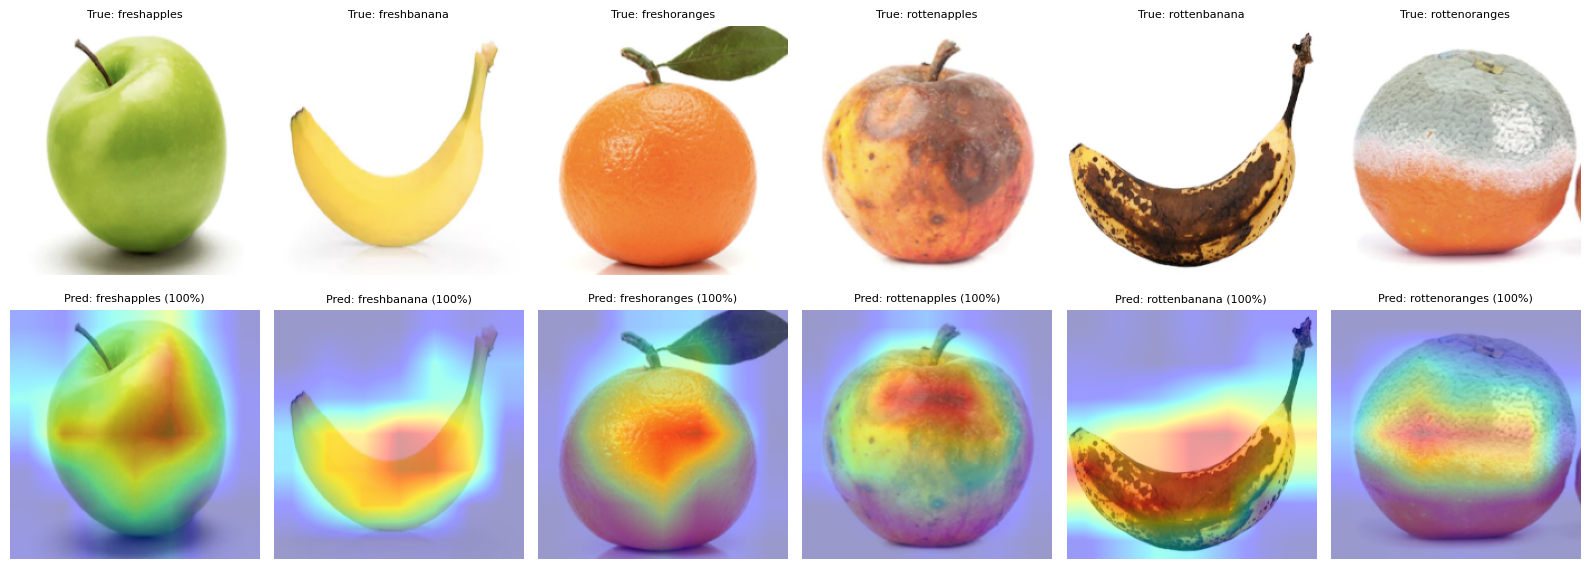

In [23]:
import matplotlib.cm as cm

base_layer = [l for l in best_mobilenet.layers
              if 'mobilenet' in l.name.lower() and isinstance(l, keras.Model)][0]
head_layers = best_mobilenet.layers[best_mobilenet.layers.index(base_layer) + 1:]
feat_model = keras.Model(
    base_layer.input,
    [base_layer.get_layer('out_relu').output, base_layer.output])

def gradcam(img):  # img: (224, 224, 3), values 0-255
    x = keras.applications.mobilenet_v2.preprocess_input(
        tf.expand_dims(tf.cast(img, tf.float32), 0))
    with tf.GradientTape() as tape:
        conv_out, y = feat_model(x)
        for l in head_layers:
            y = l(y)
        pred = int(tf.argmax(y[0]))
        score = y[:, pred]
    grads = tape.gradient(score, conv_out)
    w = tf.reduce_mean(grads, axis=(0, 1, 2))
    heat = tf.nn.relu(tf.reduce_sum(conv_out[0] * w, axis=-1))
    heat = (heat / (tf.reduce_max(heat) + 1e-8)).numpy()
    return heat, pred, float(y[0, pred])

# Prathi class nunchi oka sample image
samples = {}
for imgs, labels in test_ds:
    for im, lb in zip(imgs.numpy(), labels.numpy()):
        if int(lb) not in samples:
            samples[int(lb)] = im
    if len(samples) == len(class_names):
        break

plt.figure(figsize=(16, 6))
for i, (lb, im) in enumerate(sorted(samples.items())):
    heat, pred, conf = gradcam(im)
    heat_big = tf.image.resize(heat[..., None], (224, 224)).numpy()[..., 0]
    overlay = 0.6 * im / 255.0 + 0.4 * cm.jet(heat_big)[..., :3]
    plt.subplot(2, 6, i + 1)
    plt.imshow(im.astype('uint8')); plt.axis('off')
    plt.title(f'True: {class_names[lb]}', fontsize=8)
    plt.subplot(2, 6, i + 7)
    plt.imshow(np.clip(overlay, 0, 1)); plt.axis('off')
    plt.title(f'Pred: {class_names[pred]} ({conf:.0%})', fontsize=8)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/gradcam_samples.png', dpi=150)
plt.show()

85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step
Threshold | Unsafe approvals | Sent to manual review
     0.00 |                6 |                 0.00%
     0.50 |                6 |                 0.00%
     0.70 |                4 |                 0.33%
     0.80 |                1 |                 0.67%
     0.90 |                1 |                 1.30%
     0.95 |                1 |                 2.19%
     0.99 |                0 |                 5.49%


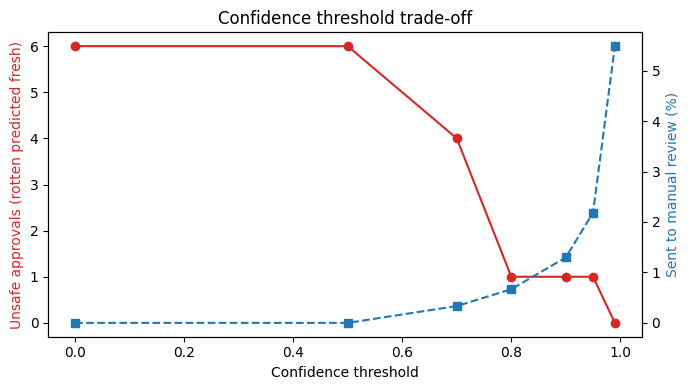

In [24]:
probs = best_mobilenet.predict(test_ds)
conf = probs.max(axis=1)
pred = probs.argmax(axis=1)
pred_fresh = np.isin(pred, fresh_idx)
true_fresh = np.isin(y_true, fresh_idx)

thresholds = [0.0, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99]
rows = []
print(f"{'Threshold':>9} | {'Unsafe approvals':>16} | {'Sent to manual review':>21}")
for t in thresholds:
    approved_fresh = pred_fresh & (conf >= t)
    unsafe = int((approved_fresh & ~true_fresh).sum())
    review = float((conf < t).mean() * 100)
    rows.append((t, unsafe, review))
    print(f"{t:>9.2f} | {unsafe:>16} | {review:>20.2f}%")

ts, us, rv = zip(*rows)
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(ts, us, 'o-', color='tab:red')
ax1.set_xlabel('Confidence threshold')
ax1.set_ylabel('Unsafe approvals (rotten predicted fresh)', color='tab:red')
ax2 = ax1.twinx()
ax2.plot(ts, rv, 's--', color='tab:blue')
ax2.set_ylabel('Sent to manual review (%)', color='tab:blue')
plt.title('Confidence threshold trade-off')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/threshold_tradeoff.png', dpi=150)
plt.show()

85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step


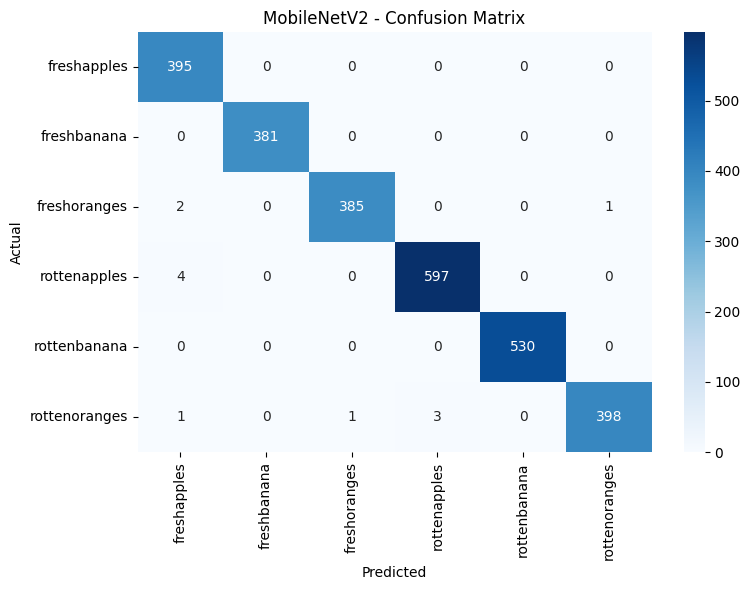

In [25]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_true = np.concatenate([y.numpy() for _, y in test_ds])
pred = np.argmax(best_mobilenet.predict(test_ds), axis=1)
cmat = confusion_matrix(y_true, pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cmat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('MobileNetV2 - Confusion Matrix')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/mobilenet_confusion_matrix.png', dpi=150)
plt.show()